<a href="https://colab.research.google.com/github/ihsann2410010447/statistika-probabilitas-uniska/blob/main/M9_Praktikum_EDA_Mall_Customers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎯 Modul 9 — Praktikum Statistik Deskriptif & EDA

### Reference Walkthrough: Mall Customers Dataset + Milestone 1 Template

**Mata Kuliah:** Statistika & Probabilitas (TIF1501)
**Program Studi:** Teknik Informatika (55201) · FTI · Uniska MAB Banjarmasin
**Semester:** 5 · 3 SKS · CPMK072 Dimulai

---

## 🎯 Tujuan Pembelajaran

1. **Menghitung** measures of central tendency (mean, median, modus) dan memilih yang tepat.
2. **Menghitung** measures of dispersion (variance, std, IQR, CV, range).
3. **Membuat** visualisasi univariat & bivariat untuk eksplorasi data.
4. **Menerapkan** framework EDA 7-langkah pada dataset Kaggle pilihan sendiri.

---

## 📋 Alur Notebook

| Bagian | Isi | Waktu |
|--------|-----|-------|
| **A** | Setup & Load Mall Customers | 5 menit |
| **B** | Inspeksi Awal & Data Quality | 10 menit |
| **C** | Central Tendency (mean/median/mode) | 10 menit |
| **D** | Dispersion (std/var/IQR/CV) | 10 menit |
| **E** | Univariate Visualization | 15 menit |
| **F** | Bivariate Visualization | 15 menit |
| **G** | Interactive Plotly Dashboard | 10 menit |
| **H** | Milestone 1 Template + Refleksi | 15 menit |

**Total: ± 90 menit**

---

## 💡 Mengapa Mall Customers?

- ✅ **200 pelanggan nyata** sebuah mall di Amerika
- ✅ Mix of types: 1 nominal (Gender) + 4 numeric (ID, Age, Income, Spending Score)
- ✅ Dataset klasik Kaggle untuk EDA + customer segmentation
- ✅ Insight bisnis nyata: pola belanja per gender, age-income-spending relationship
- ✅ Template langsung bisa diaplikasikan ke dataset pilihan mahasiswa

**Catatan**: Dataset ini adalah **REFERENSI**. Milestone 1 Anda harus memilih dataset Kaggle SENDIRI (≥500 rows, ≥5 kolom) dan apply framework yang sama.


---

# 🔧 A. Setup & Load Mall Customers


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load Mall Customers dataset
url = "https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/Machine%20Learning%20A-Z%20Template%20Folder/Part%204%20-%20Clustering/Section%2024%20-%20K-Means%20Clustering/Mall_Customers.csv"
df = pd.read_csv(url)

# Rename for easier access
df.rename(columns={
    'Genre': 'Gender',
    'Annual Income (k$)': 'Income',
    'Spending Score (1-100)': 'SpendingScore'
}, inplace=True)

print(f"Dataset berhasil dimuat!")
print(f"Shape: {df.shape[0]} baris × {df.shape[1]} kolom")
df.head()


Dataset berhasil dimuat!
Shape: 200 baris × 5 kolom


,CustomerID,Gender,Age,Income,SpendingScore
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


---

# 🔍 B. Inspeksi Awal & Data Quality


In [2]:
# Step 1: dtypes & missing values
print("=== DATA TYPES ===")
print(df.dtypes)
print("\n=== MISSING VALUES ===")
print(df.isnull().sum())
print("\n=== DUPLICATE ROWS ===")
print(f"Duplikat: {df.duplicated().sum()}")
print("\n=== MEMORY USAGE ===")
print(df.memory_usage(deep=True).sum(), "bytes")


=== DATA TYPES ===
CustomerID        int64
Gender           object
Age               int64
Income            int64
SpendingScore     int64
dtype: object

=== MISSING VALUES ===
CustomerID       0
Gender           0
Age              0
Income           0
SpendingScore    0
dtype: int64

=== DUPLICATE ROWS ===
Duplikat: 0

=== MEMORY USAGE ===
17356 bytes


In [3]:
# Step 2: Statistik deskriptif ringkasan (otomatis via describe)
print("=== DESCRIBE NUMERIC ===")
df.describe().round(2)


=== DESCRIBE NUMERIC ===


,CustomerID,Age,Income,SpendingScore
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


In [4]:
# Describe categorical (Gender)
print("=== DESCRIBE CATEGORICAL ===")
df['Gender'].value_counts()


=== DESCRIBE CATEGORICAL ===


,count
Gender,
Female,112
Male,88


---

# 📊 C. Measures of Central Tendency

**Tujuan Pembelajaran 1** — Mean, Median, Modus per kolom numerik.


In [5]:
# Pilih kolom numerik (kecuali CustomerID)
numeric_cols = ['Age', 'Income', 'SpendingScore']

central = pd.DataFrame({
    'Mean': df[numeric_cols].mean().round(2),
    'Median': df[numeric_cols].median().round(2),
    'Modus': df[numeric_cols].mode().iloc[0].round(2),
    'Diff (Mean-Median)': (df[numeric_cols].mean() - df[numeric_cols].median()).round(2),
})

print("CENTRAL TENDENCY per kolom numerik:\n")
print(central)
print("\n💡 Jika Mean > Median → right-skewed")
print("   Jika Mean < Median → left-skewed")
print("   Jika Mean ≈ Median → symmetric")


CENTRAL TENDENCY per kolom numerik:

                Mean  Median  Modus  Diff (Mean-Median)
Age            38.85    36.0   32.0                2.85
Income         60.56    61.5   54.0               -0.94
SpendingScore  50.20    50.0   42.0                0.20

💡 Jika Mean > Median → right-skewed
   Jika Mean < Median → left-skewed
   Jika Mean ≈ Median → symmetric


In [6]:
# Interpretasi otomatis
print("INTERPRETASI DISTRIBUSI:")
for col in numeric_cols:
    mean = df[col].mean()
    median = df[col].median()
    diff = (mean - median) / median * 100
    if abs(diff) < 2:
        shape = "SYMMETRIC (dekat Normal)"
    elif diff > 0:
        shape = f"RIGHT-SKEWED (mean {diff:.1f}% > median)"
    else:
        shape = f"LEFT-SKEWED (mean {diff:.1f}% < median)"
    print(f"  {col:<15}: {shape}")

# Modus untuk Gender (categorical)
print(f"\nModus Gender: {df['Gender'].mode()[0]} ({df['Gender'].value_counts().iloc[0]} orang)")


INTERPRETASI DISTRIBUSI:
  Age            : RIGHT-SKEWED (mean 7.9% > median)
  Income         : SYMMETRIC (dekat Normal)
  SpendingScore  : SYMMETRIC (dekat Normal)

Modus Gender: Female (112 orang)


---

# 📏 D. Measures of Dispersion

**Tujuan Pembelajaran 2** — Variance, Std, IQR, CV.


In [7]:
dispersion = pd.DataFrame({
    'Range': df[numeric_cols].max() - df[numeric_cols].min(),
    'Variance': df[numeric_cols].var().round(2),
    'Std Dev': df[numeric_cols].std().round(2),
    'Q1': df[numeric_cols].quantile(0.25),
    'Q3': df[numeric_cols].quantile(0.75),
    'IQR': df[numeric_cols].quantile(0.75) - df[numeric_cols].quantile(0.25),
    'CV (%)': (df[numeric_cols].std() / df[numeric_cols].mean() * 100).round(2),
})

print("DISPERSION per kolom numerik:\n")
print(dispersion)
print("\n💡 CV tinggi = variasi relatif besar (bagus untuk bandingkan antar kolom)")
print("   IQR = robust terhadap outlier")


DISPERSION per kolom numerik:

               Range  Variance  Std Dev     Q1    Q3    IQR  CV (%)
Age               52    195.13    13.97  28.75  49.0  20.25   35.96
Income           122    689.84    26.26  41.50  78.0  36.50   43.37
SpendingScore     98    666.85    25.82  34.75  73.0  38.25   51.44

💡 CV tinggi = variasi relatif besar (bagus untuk bandingkan antar kolom)
   IQR = robust terhadap outlier


In [8]:
# Interpretasi CV
print("INTERPRETASI COEFFICIENT OF VARIATION (CV):")
for col in numeric_cols:
    cv = df[col].std() / df[col].mean() * 100
    if cv < 15:
        level = "RENDAH — data cukup konsisten"
    elif cv < 30:
        level = "SEDANG — variasi wajar"
    else:
        level = "TINGGI — variasi besar antar observasi"
    print(f"  {col:<15}: CV = {cv:.1f}% → {level}")


INTERPRETASI COEFFICIENT OF VARIATION (CV):
  Age            : CV = 36.0% → TINGGI — variasi besar antar observasi
  Income         : CV = 43.4% → TINGGI — variasi besar antar observasi
  SpendingScore  : CV = 51.4% → TINGGI — variasi besar antar observasi


---

# 📊 E. Univariate Visualization

**Tujuan Pembelajaran 3** — Histogram, boxplot, violin, countplot.


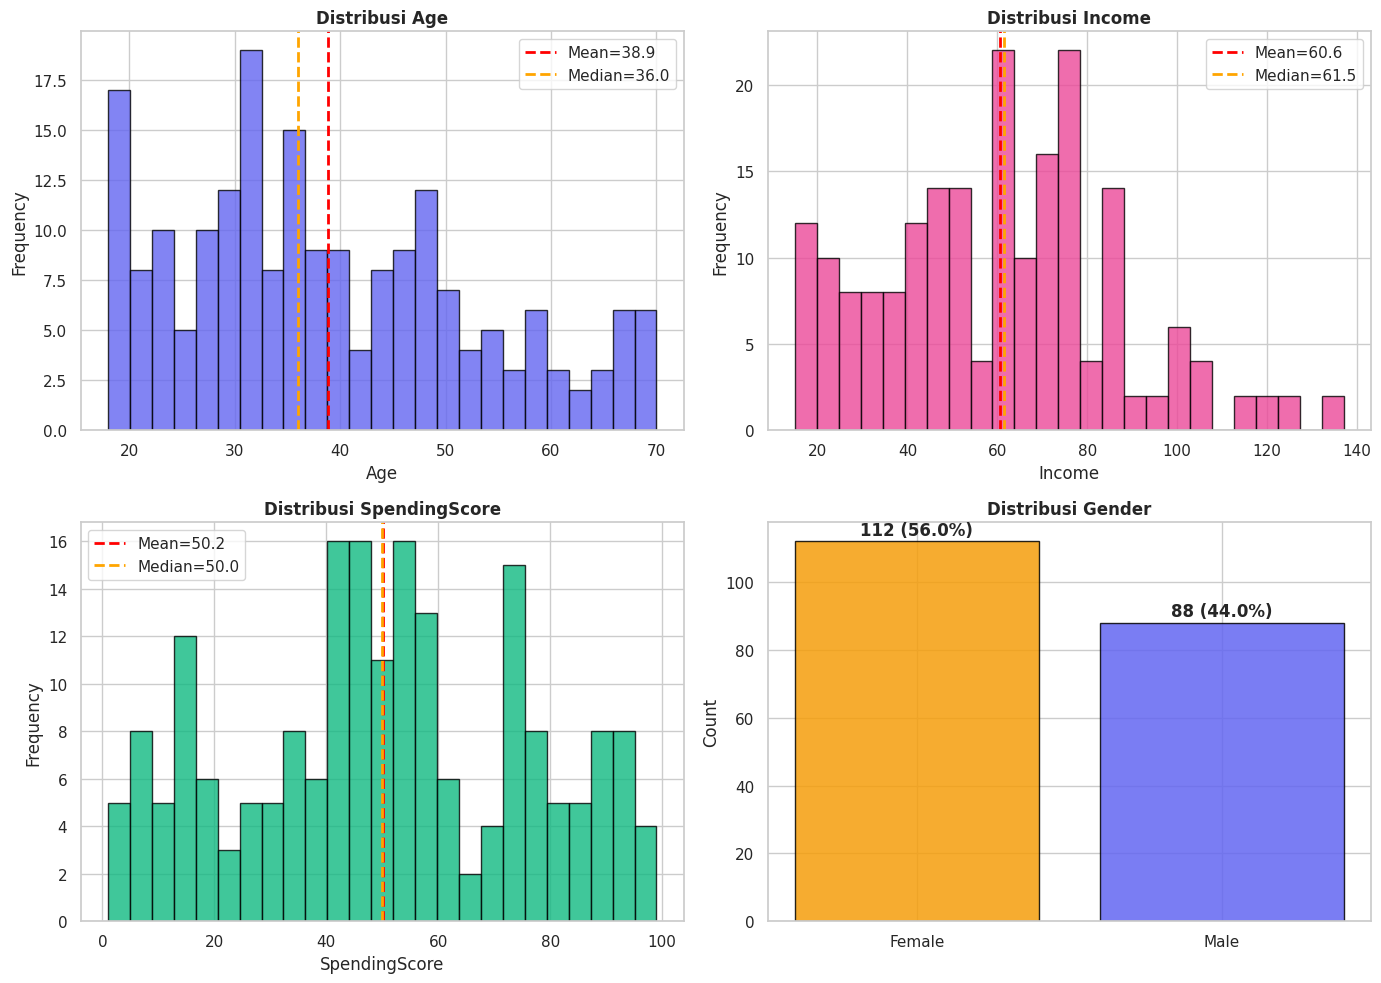

In [9]:
# 2x2 grid: histogram untuk 3 numerik + countplot gender
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col, color in zip(axes.flatten()[:3], numeric_cols, ['#6366F1', '#EC4899', '#10B981']):
    df[col].hist(bins=25, ax=ax, color=color, edgecolor='black', alpha=0.8)
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean={df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='orange', linestyle='--', linewidth=2, label=f'Median={df[col].median():.1f}')
    ax.set_title(f'Distribusi {col}', fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.legend()

# Gender countplot
ax = axes[1, 1]
counts = df['Gender'].value_counts()
bars = ax.bar(counts.index, counts.values, color=['#F59E0B', '#6366F1'], edgecolor='black', alpha=0.85)
ax.set_title('Distribusi Gender', fontweight='bold')
ax.set_ylabel('Count')
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
            f'{val} ({val/len(df)*100:.1f}%)', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


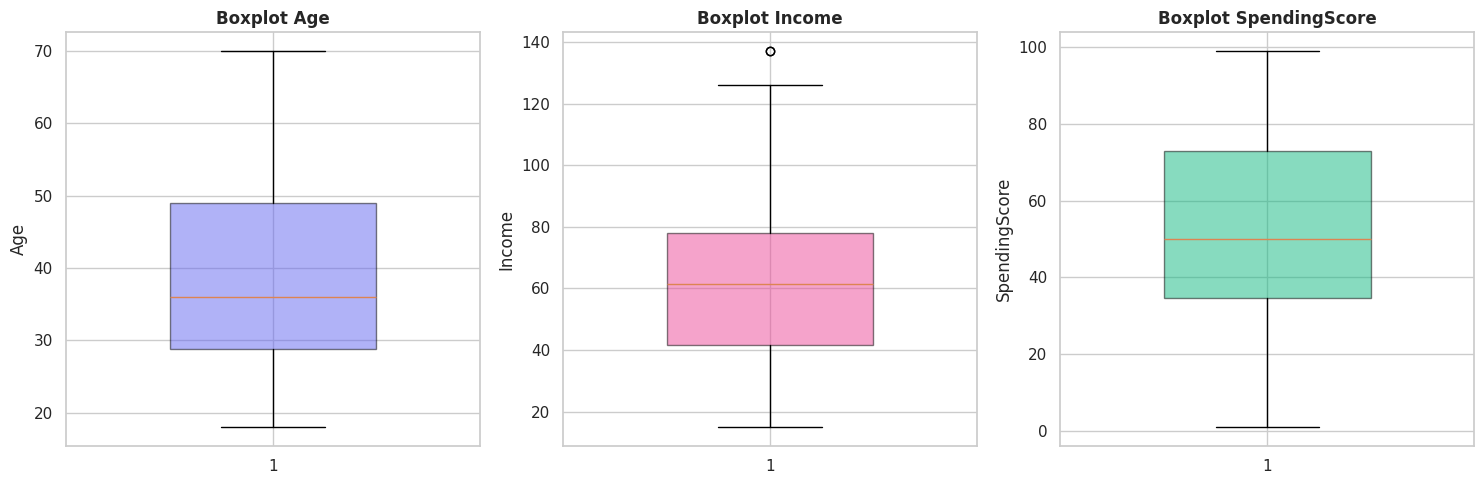


=== DETEKSI OUTLIER (IQR method) ===
  Age            : 0 outlier (<-1.6 atau >79.4)
  Income         : 2 outlier (<-13.2 atau >132.8)
  SpendingScore  : 0 outlier (<-22.6 atau >130.4)


In [10]:
# Boxplot untuk deteksi outlier
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col, color in zip(axes, numeric_cols, ['#6366F1', '#EC4899', '#10B981']):
    bp = ax.boxplot(df[col], patch_artist=True, widths=0.5)
    bp['boxes'][0].set_facecolor(color)
    bp['boxes'][0].set_alpha(0.5)
    ax.set_title(f'Boxplot {col}', fontweight='bold')
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

# Deteksi outlier via IQR
print("\n=== DETEKSI OUTLIER (IQR method) ===")
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)]
    print(f"  {col:<15}: {len(outliers)} outlier (<{Q1-1.5*IQR:.1f} atau >{Q3+1.5*IQR:.1f})")


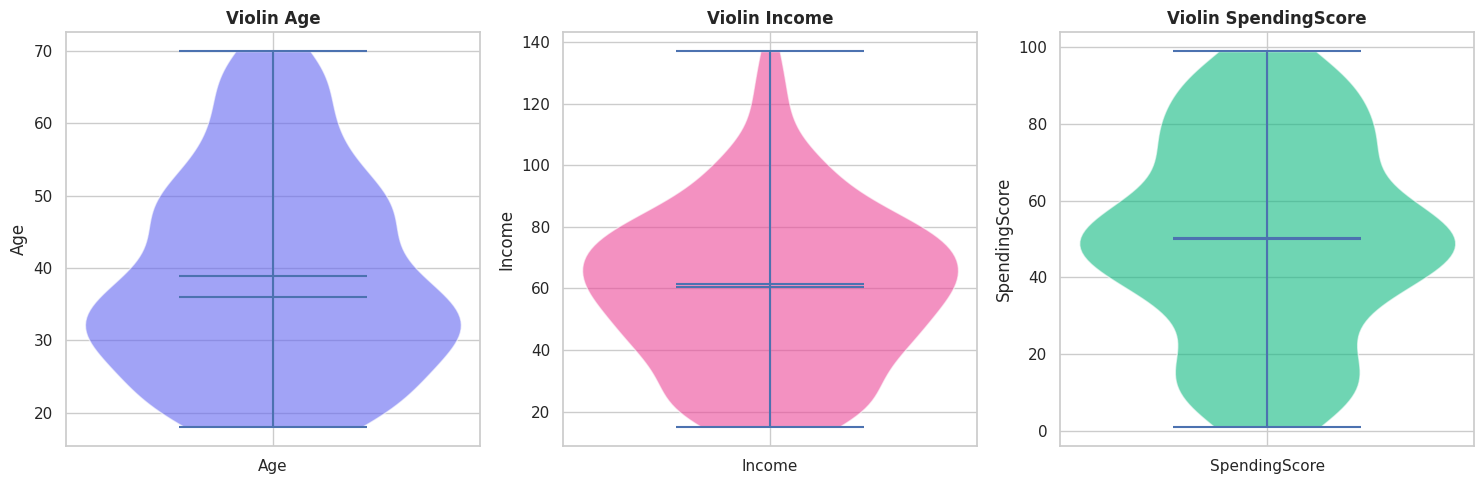

In [11]:
# Violin plot — distribusi + density
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col, color in zip(axes, numeric_cols, ['#6366F1', '#EC4899', '#10B981']):
    parts = ax.violinplot(df[col], widths=0.6, showmeans=True, showmedians=True)
    for pc in parts['bodies']:
        pc.set_facecolor(color)
        pc.set_alpha(0.6)
    ax.set_title(f'Violin {col}', fontweight='bold')
    ax.set_ylabel(col)
    ax.set_xticks([1])
    ax.set_xticklabels([col])

plt.tight_layout()
plt.show()


---

# 🔗 F. Bivariate Visualization

**Tujuan Pembelajaran 3** — Scatter, correlation heatmap, pair plot, grouped boxplot.


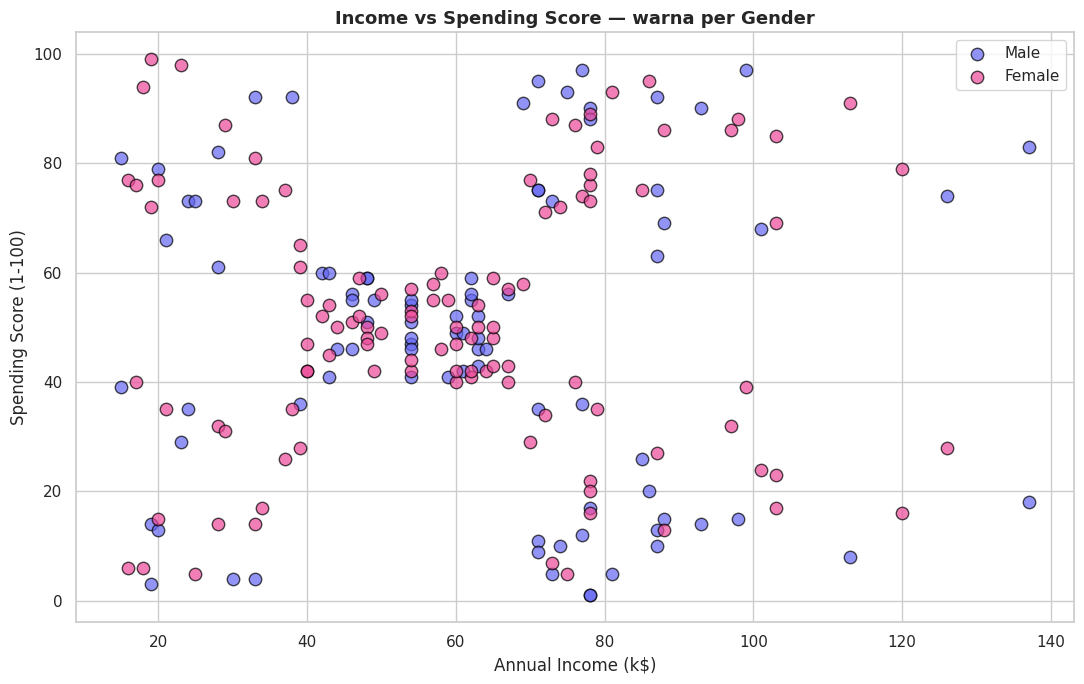


💡 Visual terlihat 5 cluster alami — ini landasan customer segmentation!


In [12]:
# Scatter: Income vs SpendingScore (dengan warna Gender)
fig, ax = plt.subplots(figsize=(11, 7))
for gender, color in [('Male', '#6366F1'), ('Female', '#EC4899')]:
    sub = df[df['Gender'] == gender]
    ax.scatter(sub['Income'], sub['SpendingScore'], c=color, label=gender, s=80, alpha=0.7, edgecolors='black')

ax.set_xlabel('Annual Income (k$)', fontsize=12)
ax.set_ylabel('Spending Score (1-100)', fontsize=12)
ax.set_title('Income vs Spending Score — warna per Gender', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

print("\n💡 Visual terlihat 5 cluster alami — ini landasan customer segmentation!")


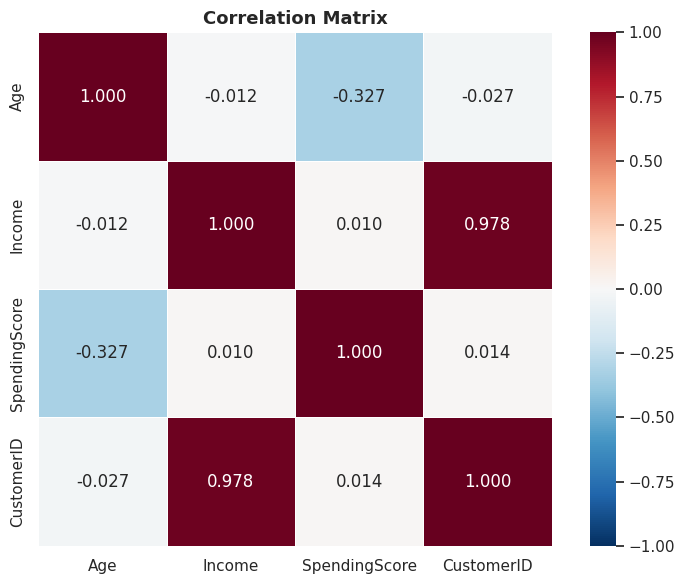


💡 PENTING: CustomerID korelasi 0.978 dengan Income — ini artifact karena data diurutkan!
   Drop CustomerID sebelum analisis lanjut.


In [13]:
# Correlation heatmap
fig, ax = plt.subplots(figsize=(8, 6))
corr = df[numeric_cols + ['CustomerID']].corr()
sns.heatmap(corr, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=ax, linewidths=0.5, square=True)
ax.set_title('Correlation Matrix', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

print("\n💡 PENTING: CustomerID korelasi 0.978 dengan Income — ini artifact karena data diurutkan!")
print("   Drop CustomerID sebelum analisis lanjut.")


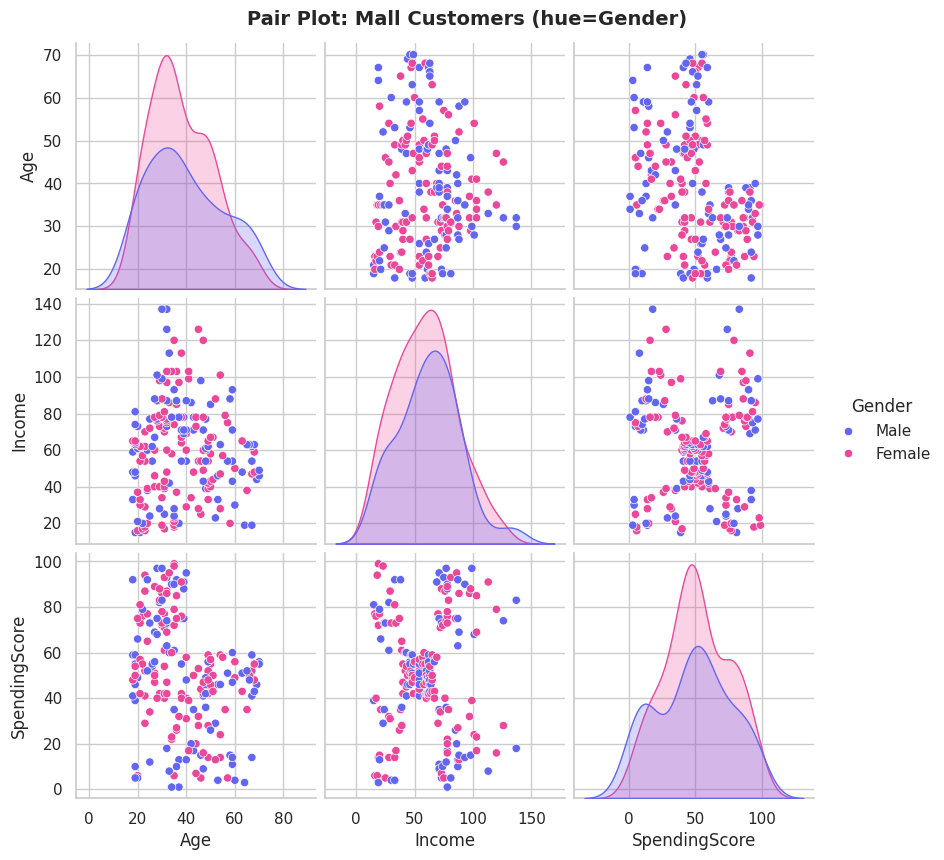

In [14]:
# Pair plot — scatter matrix semua pasangan numerik
g = sns.pairplot(df[numeric_cols + ['Gender']], hue='Gender',
                 palette={'Male': '#6366F1', 'Female': '#EC4899'},
                 diag_kind='kde', height=2.8)
g.fig.suptitle('Pair Plot: Mall Customers (hue=Gender)', y=1.02, fontsize=14, fontweight='bold')
plt.show()


/tmp/ipykernel_559/3313872228.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Gender', y=col, data=df, ax=ax,
/tmp/ipykernel_559/3313872228.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Gender', y=col, data=df, ax=ax,
/tmp/ipykernel_559/3313872228.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Gender', y=col, data=df, ax=ax,


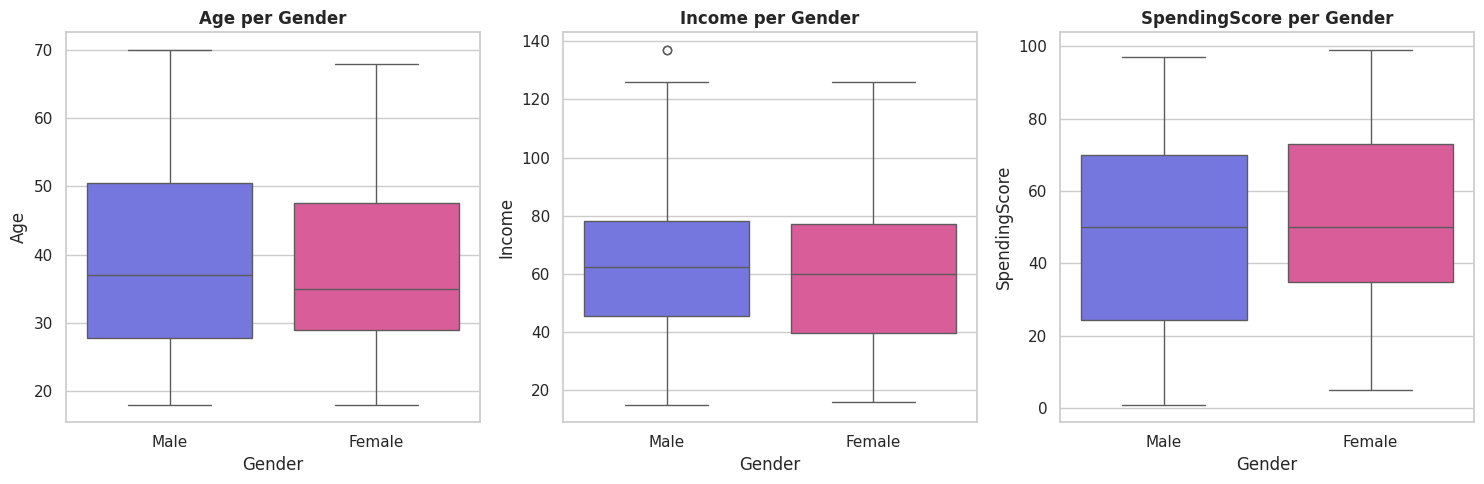


=== PERBANDINGAN MEAN per GENDER ===
          Age  Income  SpendingScore
Gender                              
Female  38.10   59.25          51.53
Male    39.81   62.23          48.51


In [15]:
# Grouped boxplot: bandingkan metric per Gender
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x='Gender', y=col, data=df, ax=ax,
                palette={'Male': '#6366F1', 'Female': '#EC4899'})
    ax.set_title(f'{col} per Gender', fontweight='bold')

plt.tight_layout()
plt.show()

# Statistical comparison
print("\n=== PERBANDINGAN MEAN per GENDER ===")
print(df.groupby('Gender')[numeric_cols].mean().round(2))


---

# 📊 G. Interactive Plotly Dashboard

**Tujuan Pembelajaran 4** — Dashboard interactive siap-share.


In [16]:
# Interactive scatter dengan hover info
fig = px.scatter(df, x='Income', y='SpendingScore',
                 color='Gender', size='Age',
                 hover_data=['CustomerID', 'Age'],
                 title='Mall Customers: Income vs Spending Score (interaktif)',
                 color_discrete_map={'Male': '#6366F1', 'Female': '#EC4899'},
                 size_max=25)
fig.update_layout(width=900, height=500, font=dict(size=12))
fig.show()


In [17]:
# Multi-panel dashboard
fig = make_subplots(rows=2, cols=2,
                    subplot_titles=('Distribusi Age', 'Distribusi Income',
                                    'Distribusi Spending Score', 'Gender Breakdown'),
                    specs=[[{'type':'histogram'}, {'type':'histogram'}],
                           [{'type':'histogram'}, {'type':'pie'}]])

fig.add_trace(go.Histogram(x=df['Age'], marker_color='#6366F1', nbinsx=25), row=1, col=1)
fig.add_trace(go.Histogram(x=df['Income'], marker_color='#EC4899', nbinsx=25), row=1, col=2)
fig.add_trace(go.Histogram(x=df['SpendingScore'], marker_color='#10B981', nbinsx=25), row=2, col=1)

counts = df['Gender'].value_counts()
fig.add_trace(go.Pie(labels=counts.index, values=counts.values,
                     marker=dict(colors=['#EC4899', '#6366F1'])), row=2, col=2)

fig.update_layout(height=700, width=1000, showlegend=False,
                  title_text='Mall Customers Interactive Dashboard',
                  title_font_size=16)
fig.show()


---

# 📝 H. Milestone 1 Template + Refleksi

## H.1 Insight dari Mall Customers (Reference)

Dari EDA di atas, berikut 5 insight bisnis yang bisa diambil:

1. **Gender Balance**: 56% Female, 44% Male — sedikit skew ke perempuan.
2. **Age Distribusi**: slight right-skewed (mean 38.9 > median 36), rentang 18-70 tahun.
3. **Income vs Spending TIDAK ada korelasi linier** (r ≈ 0.01) — insight kunci untuk segmentasi.
4. **5 cluster alami terlihat di scatter Income vs Spending** → landasan K-Means (M12+).
5. **Spending Score simetris** (mean=median=50) — mungkin skor dirancang dengan normalisasi.

## H.2 Template Milestone 1 untuk Dataset Anda

Setelah menyelesaikan reference di atas, buat notebook baru untuk dataset pilihan Anda:


In [18]:
# =========================================================
# TEMPLATE MILESTONE 1 — ganti URL dengan dataset Anda
# =========================================================

# STEP 1: Load Dataset
# URL = "<URL raw CSV dataset Kaggle Anda>"
# df_my = pd.read_csv(URL)
# print(f"Shape: {df_my.shape}")
# df_my.head()

# STEP 2: Missing & Duplicate Check
# print(df_my.isnull().sum())
# print(f"Duplicates: {df_my.duplicated().sum()}")

# STEP 3: Central Tendency
# numeric = df_my.select_dtypes(include='number').columns.tolist()
# print(df_my[numeric].describe())

# STEP 4: Dispersion
# print({c: {'std': df_my[c].std(), 'IQR': df_my[c].quantile(0.75) - df_my[c].quantile(0.25),
#            'CV': df_my[c].std() / df_my[c].mean() * 100} for c in numeric})

# STEP 5: Univariate Viz — min 3 histogram/boxplot
# (contoh kode ada di cell sebelumnya, adaptasi untuk kolom Anda)

# STEP 6: Bivariate Viz — min scatter + heatmap
# sns.heatmap(df_my[numeric].corr(), annot=True, cmap='RdBu_r', center=0)

# STEP 7: 3-5 Insight tertulis (markdown cell)
# - Insight 1: ...
# - Insight 2: ...
# - Insight 3: ...

print("💡 Copy template ini ke notebook baru, ganti URL dan nama kolom.")
print("   Submit sebelum Modul 10 dimulai (link GitHub via LMS).")


💡 Copy template ini ke notebook baru, ganti URL dan nama kolom.
   Submit sebelum Modul 10 dimulai (link GitHub via LMS).


## H.3 Pertanyaan Refleksi

Jawab 5 pertanyaan berikut di cell markdown di bawah:

1. **Mean vs Median**: Pada kolom Income Mall Customers, mean=60.6 dan median=61.5 — hampir sama. Jelaskan apa artinya untuk bentuk distribusi dan implikasi pada pemilihan ukuran pemusatan.

2. **CustomerID artifact**: Korelasi CustomerID dengan Income adalah 0.978 — bukan karena ID "menyebabkan" Income tinggi, tapi karena data terurut. Sebutkan 1 contoh lain dari "spurious correlation" di dunia nyata dan bahayanya.

3. **IQR vs Std Dev**: Kapan Anda memilih IQR dibanding Std Dev untuk melaporkan sebaran data? Berikan contoh kasus nyata.

4. **5 Cluster Natural**: Pada scatter Income vs Spending Score, visual menunjukkan 5 kelompok. Apa strategi bisnis mall jika terbukti ada 5 segmen? Berikan minimal 1 contoh.

5. **Dataset Milestone 1**: Dataset apa yang Anda pilih untuk Milestone 1? Jelaskan sumber, konteks bisnis, dan 3 pertanyaan yang ingin Anda jawab melalui EDA.

### ✏️ Jawaban Anda:

**1.** **Mean vs Median pada Distribusi Income:**
* **Bentuk Distribusi:** Karena nilai Mean (60.56) hampir sama dengan Median (61.50), ini menandakan bahwa distribusi data pendapatan (*Income*) pelanggan bersifat **simetris (mendekati distribusi normal)** tanpa adanya kemiringan (*skewness*) yang berarti.
* **Implikasi Pemilihan Ukuran Pemusatan:** Dalam kondisi data yang simetris tanpa pencilan ekstrem, **Mean (Rata-rata)** adalah pilihan terbaik karena efisien dan memanfaatkan seluruh titik data yang tersedia. Namun, karena nilainya sangat berdekatan, baik Mean maupun Median dapat merepresentasikan pusat data dengan sangat baik.

**2.** **Contoh Spurious Correlation & Bahayanya:**
* **Contoh Nyata:** Korelasi positif yang sangat kuat antara *jumlah penjualan es krim* dan *jumlah kasus orang tenggelam di pantai* pada bulan-bulan tertentu. Kedua hal ini sebenarnya tidak saling memengaruhi, melainkan sama-sama dipengaruhi oleh variabel ketiga (*confounding variable*), yaitu **suhu musim panas**.
* **Bahayanya:** Mengasumsikan adanya hubungan kausalitas (sebab-akibat) dari korelasi palsu ini dapat memicu keputusan yang salah dan fatal. Misalnya, pemerintah melarang penjualan es krim dengan harapan angka kematian akibat tenggelam menurun, yang mana tindakan tersebut sepenuhnya tidak efektif dan merugikan ekonomi lokal.

**3.** **Pemilihan IQR dibanding Standard Deviation:**
* **Kapan memilih IQR:** Kita menggunakan **IQR** ketika dataset yang dihadapi memiliki **distribusi yang sangat miring (skewed)** atau mengandung **outlier (pencilan) ekstrem**.
* **Contoh Kasus Nyata:** Analisis data *Gaji Karyawan* di sebuah perusahaan teknologi berskala besar. Sebagian besar karyawan memiliki gaji dalam rentang standar, namun ada beberapa eksekutif (C-level) dengan gaji yang luar biasa tinggi. Jika menggunakan Standard Deviation, nilai sebaran akan membengkak secara tidak realistis karena sangat sensitif terhadap pencilan. IQR menjadi pilihan yang lebih stabil (*robust*) karena hanya fokus pada sebaran 50% data di bagian tengah.

**4.** **Strategi Bisnis untuk 5 Segmen Pelanggan:**
* **Strategi Konkrit:** Dengan teridentifikasinya 5 segmen (misal: *High Income-High Spend*, *High Income-Low Spend*, *Low Income-High Spend*, *Low Income-Low Spend*, dan *Average Spend*), mall dapat meluncurkan kampanye pemasaran yang dipersonalisasi.
* **Contoh:** Untuk segmen **High Income - Low Spend** (pelanggan mampu namun pasif), mall dapat mengirimkan undangan eksklusif ke acara pameran privat produk mewah atau menawarkan layanan *personal shopper* gratis guna memicu ketertarikan mereka untuk mulai berbelanja di dalam mall.

**5.** **Rancangan Dataset Milestone 1:**
* **Dataset:** *E-Commerce Sales and Customer Behavior Dataset* dari Kaggle.
* **Konteks Bisnis:** Menganalisis transaksi ritel online untuk merumuskan strategi promosi musiman dan manajemen stok produk yang lebih efektif.
* **3 Pertanyaan EDA:**
  1. Kategori produk mana yang menghasilkan total nilai transaksi (*GMV*) dan keuntungan terbesar?
  2. Apakah ada perbedaan pola waktu belanja yang signifikan antara kelompok pelanggan dengan tingkat keanggotaan (Membership) gratis dan premium?
  3. Bagaimana pengaruh besaran nilai diskon terhadap tingkat retensi pembelian kembali oleh pelanggan?

## H.4 Checklist Submit Milestone 1

### Reference Walkthrough (notebook ini):
- [ ] Semua cell sukses dijalankan tanpa error
- [ ] Central tendency table muncul lengkap
- [ ] Dispersion table muncul lengkap
- [ ] Histogram + boxplot + violin + countplot muncul
- [ ] Scatter + heatmap + pairplot muncul
- [ ] Plotly dashboard interaktif
- [ ] 5 pertanyaan refleksi dijawab

### Milestone 1 Deliverable (notebook SENDIRI):
- [ ] Dataset Kaggle pilihan (≥500 rows, ≥5 kolom, bukan Mall Customers)
- [ ] Framework EDA 7-langkah lengkap
- [ ] Minimal 6 visualisasi (3 univariat + 3 bivariat)
- [ ] 1 interactive Plotly dashboard (minimal 2 chart)
- [ ] 3-5 insight tertulis dengan evidence
- [ ] Daftar 2-3 hipotesis untuk Milestone 2 (M10 hypothesis testing)
- [ ] README.md dengan: deskripsi dataset, sumber, cara menjalankan, ringkasan insight
- [ ] Repo GitHub ter-commit dan link dikumpulkan via LMS

### Deadline: SEBELUM pertemuan Modul 10 dimulai.

## H.5 Push ke GitHub

1. Buat repository baru: `projek-statistika-<nama>` di GitHub
2. Upload notebook, README, dan screenshot dashboard
3. Commit message: `"Milestone 1: EDA dataset <nama-dataset>"`
4. Submit link repo via LMS Uniska

---

## 🎓 Selamat! Anda Berhasil...

✅ Menghitung semua measures of central tendency dan dispersion
✅ Membuat 6 jenis visualisasi berbeda
✅ Membangun interactive Plotly dashboard
✅ Mengekstrak 5 insight bisnis dari dataset
✅ Siap aplikasi ke Milestone 1 dengan dataset pilihan sendiri

## 📚 Bacaan Lanjutan

- **Bruce, P.** (2020). *Practical Statistics for Data Scientists*, Chapter 1 (Exploratory Data Analysis).
- **Tukey, J.** (1977). *Exploratory Data Analysis* — pionir boxplot & five-number summary.
- **Plotly Documentation** — interactive dashboards: https://plotly.com/python/
- **Seaborn Gallery** — https://seaborn.pydata.org/examples/

## 🔮 Persiapan Modul 10

Modul 10 — **Inferential Statistics & Hypothesis Testing**:
- Confidence Interval (CI 95%)
- t-test, chi-square, ANOVA
- p-value interpretation
- **Milestone 2**: Uji 2-3 hipotesis yang Anda formulasikan di akhir M9

**Sebelum M10:**
1. Selesaikan Milestone 1 EDA, push ke GitHub
2. Formulasikan 3 hipotesis dari insight Milestone 1 Anda
3. Baca Bruce Ch. 3 (Statistical Experiments and Significance Testing)

---

*Notebook by: Prodi Teknik Informatika · Uniska MAB Banjarmasin · Edisi 2026*
